### **Fourier/DFT (Discrete Fourier Transform)**

___

**F1 (ทฤษฎี + โค้ด) จำนวนเชิงซ้อนและสูตรของออยเลอร์ — อ่าน ThinkDSP บทที่ 7 หัวข้อ 7.1 Complex exponentials**
  - **ทำ:**
    - สร้าง notebook ใหม่ `notebooks/05_DFT.ipynb`
    - `z = 3 + 4j` → print `z.real`, `z.imag`, `np.abs(z)`, `np.angle(z)`
    - ทำนายก่อนรัน: `np.exp(1j*θ)` ที่ θ = 0, π/2, π, 3π/2 เขียนเป็น a + bj ลง markdown
      **ตอบ** ทำนายก่อนรัน: 
        1. np.exp(1j*0) = 1 + 0j
        2. np.exp(1j*(π/2)) = 0 + 1j
        3. np.exp(1j*(π)) = -1 + 0j
        4. np.exp(1j*(3π/2)) = 0 - 1j
    - รันเช็คทั้ง 4 ค่าด้วย `np.round(..., 3)`
    - `sr = 1000` สร้าง `t` 1 วินาที → `z2 = np.exp(1j * 2*np.pi * 2 * t)`
    - พล็อต `z2.real` และ `z2.imag` เทียบ `t` ในกราฟเดียว (มี legend)
    - พล็อต `z2.real` (แกน x) กับ `z2.imag` (แกน y) ใช้ `plt.axis('equal')`
    - เช็ค `np.allclose(np.abs(z2), 1)`
  - **เครื่องมือใหม่:**
    - `1j` คือ j (√−1) ใน Python: `(1 + 2j) * 1j` → `(-2+1j)`
    - `np.abs(1 + 1j)` → 1.414 (ระยะจากจุด 0) และ `np.angle(1j)` → 1.5708 (มุมเป็นเรเดียน)
  - **ตอบ:**
    1. $e^{j\pi/2}$ เท่ากับเท่าไร (เขียนแบบ a + bj)\
    > $e^{j\pi/2}$ มีค่าเท่ากับ 0 + 1j
    2. ส่วน real ของ `z2` เป็นคลื่น cos หรือ sin\
    > ส่วน real ของ z2 เป็นคลื่น cos
    3. กราฟ real กับ imag ได้รูปทรงอะไร\
    > กราฟ real กับ imag เป็นรูปทรงวงกลม
  - **ใบ้:** `-0` ที่เห็นในผล ถือว่าเป็น 0
  - **เสร็จเมื่อ:** print ได้ 3.0, 4.0, 5.0, ≈0.927 / ทั้ง 4 ค่าได้ 1, j, −1, −j / `np.allclose` ได้ True / มีกราฟ 2 รูป และตอบครบ 3 ข้อ

In [1]:
%load_ext autoreload 
%autoreload 2
import sys, os
import time
import numpy as np 
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(".."))
from dsp.similarity import cosine_similarity
from dsp.signal_generator import make_time, create_sin

In [2]:
z = 3 + 4j
print(f'Real Component of z : {z.real}')
print(f'Imaginary Component of z : {z.imag}')
print(f'Magnitude of z : {np.abs(z)}')
print(f'Angle of z : {np.angle(z):.3f}')

Real Component of z : 3.0
Imaginary Component of z : 4.0
Magnitude of z : 5.0
Angle of z : 0.927


In [3]:
print(f'np.exp(1j*θ) when θ = 0 : {np.round(np.exp(1j*0), 3)}')
print(f'np.exp(1j*θ) when θ = π/2 : {np.round(np.exp(1j*(np.pi/2)), 3)}')
print(f'np.exp(1j*θ) when θ = π :{np.round(np.exp(1j*(np.pi)), 3)}')
print(f'np.exp(1j*θ) when θ = 3π/2 :{np.round(np.exp(1j*((3 * np.pi)/2)), 3)}')


np.exp(1j*θ) when θ = 0 : (1+0j)
np.exp(1j*θ) when θ = π/2 : 1j
np.exp(1j*θ) when θ = π :(-1+0j)
np.exp(1j*θ) when θ = 3π/2 :(-0-1j)


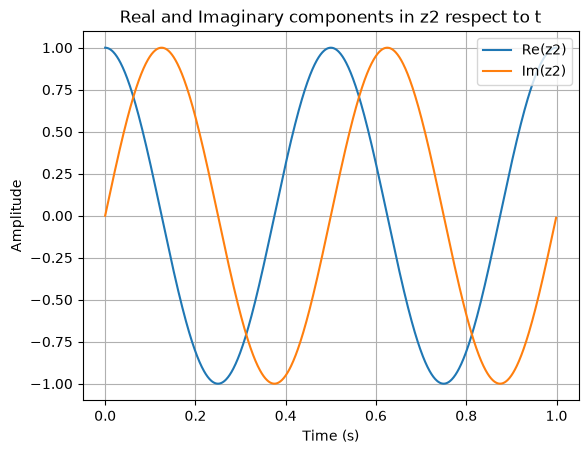

In [4]:
sr = 1000
t = make_time(0, 1, sr)
z2  = np.exp(1j * 2 * np.pi * 2 * t)

# Plot z2.real, z2.imag respect to t
fig, ax = plt.subplots()
ax.set(xlabel="Time (s)", ylabel="Amplitude", title="Real and Imaginary components in z2 respect to t")
ax.grid()
ax.plot(t, z2.real, label="Re(z2)")
ax.plot(t, z2.imag, label="Im(z2)")
ax.legend(loc="upper right")
plt.show()

(np.float64(-1.1), np.float64(1.1), np.float64(-1.1), np.float64(1.1))

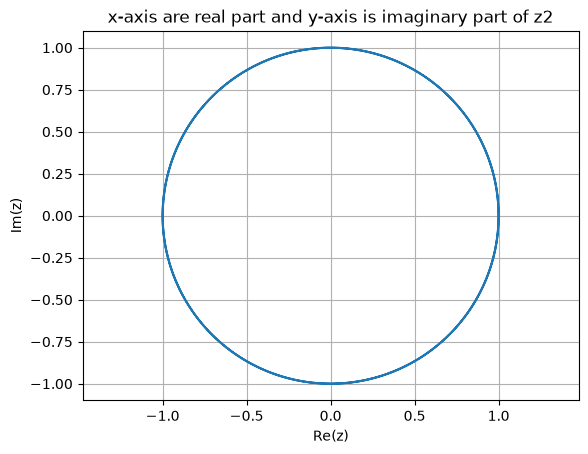

In [5]:
# Plot z.real is x-axis and z.imag is y-axis
fig, ax = plt.subplots()
ax.set(xlabel="Re(z)", ylabel="Im(z)", title="x-axis are real part and y-axis is imaginary part of z2")
ax.grid()
ax.plot(z2.real, z2.imag)
plt.axis('equal')

In [6]:
print(f"Check Magnitude of z2 : {np.allclose(np.abs(z2),1)}")

Check Magnitude of z2 : True


F2 (โค้ด) เขียน DFT เอง แล้วเทียบกับ `np.fft.fft`
  - **สูตร:** $X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j2\pi kn/N}$ สำหรับ k = 0, 1, …, N−1
  - **ทำ:**
    - เขียน `dft(x)` : loop ทีละ k → สร้าง probe $e^{-j2\pi kn/N}$ โดย `n = np.arange(N)` → `X[k]` = ผลรวมของ x คูณ probe
    - ทำนายก่อนรัน: `dft([1, 1, 1, 1])` ได้อะไร เขียนลง markdown
    > ทำนายผลก่อนรัน : `dft([1, 1, 1, 1])` ได้เท่ากับ 4
    - ทดสอบกับตัวเลขที่รู้คำตอบ (เช็คด้วย `np.allclose`): `[1, 0, 0, 0]` → `[1, 1, 1, 1]` / `[1, 1, 1, 1]` → `[4, 0, 0, 0]` / `[1, -1, 1, -1]` → `[0, 0, 4, 0]`
    - `np.random.seed(0)` แล้ว `x = np.random.randn(64)` → เช็ค `np.allclose(dft(x), np.fft.fft(x))`
    - `x = np.random.randn(1024)` → จับเวลา `dft(x)` และ `np.fft.fft(x)` → print เวลาทั้งสอง
  - **เครื่องมือใหม่:**
    - `np.zeros(3, dtype=complex)` → array ที่เก็บจำนวนเชิงซ้อนได้ ถ้าไม่ใส่ `dtype=complex` จะเกิด `TypeError` ตอนใส่ค่าเชิงซ้อนลงไป
    - จับเวลา: `import time` → `t0 = time.perf_counter()` → ทำงาน → `time.perf_counter() - t0` ได้เวลาเป็นวินาที
  - **ตอบ:**
    1. `dft([1, 1, 1, 1])` ได้เท่าไร
    > ผลลัพธ์จากการรันโปรแกรมมีค่าเท่ากับ [ 4.00000000e+00+0.00000000e+00j -1.83697020e-16-2.22044605e-16j 0.00000000e+00-2.44929360e-16j  3.29046455e-16-3.33066907e-16j] หรือประมาณ [4, 0, 0, 0]
    2. ที่ N = 1024 `np.fft.fft` เร็วกว่า `dft` ของโอมประมาณกี่เท่า
    > จากการเขียนโปรแกรมเพื่อคำนวณหาจำนวนเท่าของความเร็วในการคำนวณระหว่าง `np.fft.fft` เร็วกว่า `dft` ประมาณ 300-500 เท่า
  - **เสร็จเมื่อ:** ทดสอบ 3 ชุดได้ True ทั้งหมด / x สุ่ม 64 ตัวได้ True / มี print เวลา 2 ค่า (ควรต่างกันหลักร้อยเท่าขึ้นไป) และตอบครบ 2 ข้อ

In [7]:
def dft(x):
    """
        Calculates Discrete Fourier Transform (DFT)

        Formula: X[k] = sum(x(n) * (e**((-j*2*np.pi*k*n)/N)))

        Args:
            x: Input signal for DFT.

        Returns: 
            Array of DFT of input signal.
    """
    X = []  # list of signal after DFT
    N = len(x)
    n = np.arange(0, N) # Set n = sample of signals

    for k in range(0, N): # k = 0,1,...,N-1
        probe = np.exp((-1j * 2 * np.pi * k * n)/N)
        X.append(np.dot(x, probe))

    return np.array(X)

print(f"Check with dft([1, 1, 1, 1]) : {dft([1, 1, 1, 1])}")

Check with dft([1, 1, 1, 1]) : [ 4.00000000e+00+0.00000000e+00j -1.83697020e-16-2.22044605e-16j
  0.00000000e+00-2.44929360e-16j  3.29046455e-16-3.33066907e-16j]


In [8]:
# test output function dft()
print(np.allclose(dft([1, 0, 0, 0]), [1, 1, 1, 1]))
print(np.allclose(dft([1, 1, 1, 1]), [4, 0, 0, 0]))
print(np.allclose(dft([1, -1, 1, -1]), [0, 0, 4, 0]))

True
True
True


In [9]:
# test with random signal 64 signals
random_64_x = np.random.randn(64)
print(np.allclose(dft(random_64_x), np.fft.fft(random_64_x)))

True


In [10]:
# Counting time to calculate with dft and fft
random_1024_x = np.random.randn(1024)
# DFT
start_time = time.perf_counter()    # Set time start
result_dft = dft(random_1024_x)
end_time = time.perf_counter()
elapsed_time_dft = end_time - start_time

# FFT
start_time = time.perf_counter()    # Set time start
result_fft = np.fft.fft(random_1024_x)
end_time = time.perf_counter()
elapsed_time_fft = end_time - start_time

print(f"Calculation time DFT is : {elapsed_time_dft:.6f} seconds")
print(f"Calculation time FFT is : {elapsed_time_fft:.6f} seconds")

Calculation time DFT is : 0.160695 seconds
Calculation time FFT is : 0.000338 seconds


In [11]:
print(f'FFT is faster than DFT : {elapsed_time_dft/elapsed_time_fft}')

FFT is faster than DFT : 475.0085513467941
